# Lab 9- Deep Learning Model

This lab is meant to get you started in using Keras to design Deep Neural Networks. The goal here is to simply repeat your previous lab, but with DNNs.

Lecture 21 is your template: it reads the same data, builds, compiles and trains a network, plots its learning curves, and makes a ROC curve. Copy its cells and change the numbers.

Let's start with reading the data, like before. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, as in Lab 8. You will need both in Exercise 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

filename = "../Lab.7/SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]

df = pd.read_csv(filename, dtype='float64', names=VarNames)

Now let's define the samples. DNNs take long to train, so to start we use only the first 500,000 of the 5 million events for training. Once you get everything working, make the final version of your plots with more.

We keep **three** samples, because they do different jobs:

* **training**: what `fit` learns from;
* **validation**: what you watch while you work (pass it to `fit` as `validation_data`), and what you use to choose between models;
* **test**: used only at the end, to report the performance of the models you chose.

Keras works on NumPy arrays, so after doing all of the nice manipulation that pandas enables, we convert the DataFrames to NumPy arrays.

In [4]:
N_Train = 50000
N_Val = 5000
N_Test = 5000

Train_Sample=df[:N_Train]
Val_Sample=df[N_Train:N_Train+N_Val]
Test_Sample=df[N_Train+N_Val:N_Train+N_Val+N_Test]

X_Train=np.array(Train_Sample[VarNames[1:]])
y_Train=np.array(Train_Sample["signal"])

X_Val=np.array(Val_Sample[VarNames[1:]])
y_Val=np.array(Val_Sample["signal"])

X_Test=np.array(Test_Sample[VarNames[1:]])
y_Test=np.array(Test_Sample["signal"])

print(X_Train.shape, X_Val.shape, X_Test.shape)

(50000, 18) (5000, 18) (5000, 18)


## Exercise 1

You will need to create several models and make sure they are properly trained. Write a function that takes this history and plots the values versus epoch. For every model that you train in the remainder of this lab, assess:

* Has your model's performance plateaued? If not train for more epochs. 
* Compare the performance on the training and validation samples. Are you over training?

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_data = scaler.fit_transform(X_Train)
validation_data = scaler.transform(X_Val)

model = Sequential([
    Input(shape=(18,)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_data,
    y_Train,
    validation_data=(validation_data, y_Val),
    epochs=10,
    batch_size=1024
)

E0000 00:00:1795647144.080246   12170 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5139 - loss: 0.7052 - val_accuracy: 0.6486 - val_loss: 0.6094
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7002 - loss: 0.5750 - val_accuracy: 0.7368 - val_loss: 0.5429
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7414 - loss: 0.5289 - val_accuracy: 0.7464 - val_loss: 0.5133
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7551 - loss: 0.5050 - val_accuracy: 0.7548 - val_loss: 0.4970
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7646 - loss: 0.4903 - val_accuracy: 0.7606 - val_loss: 0.4862
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7724 - loss: 0.4803 - val_accuracy: 0.7650 - val_loss: 0.4788
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7772 - loss: 0.4730 - val_accuracy: 0.7694 - val_loss: 0.4730
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7807 - loss: 0.4674 - val_accuracy: 0.7714 - val_loss:

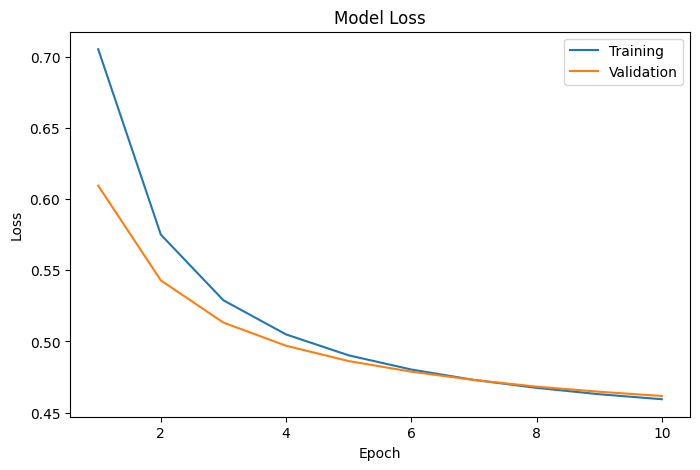

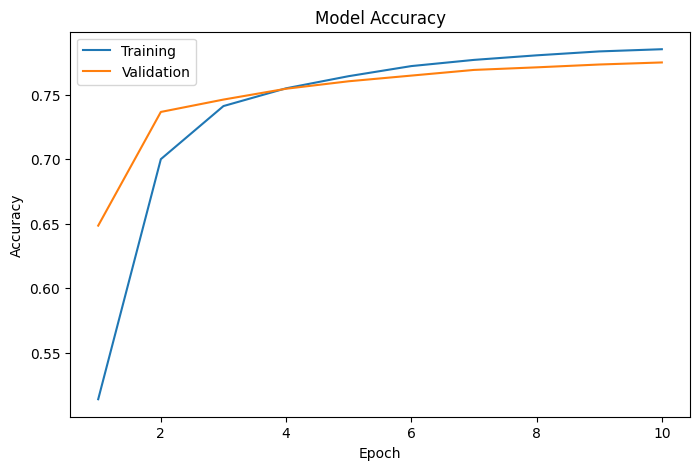

In [6]:
def plot_history(history):
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, history.history["loss"], label="Training")
    plt.plot(epochs, history.history["val_loss"], label="Validation")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Model Loss")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, history.history["accuracy"], label="Training")
    plt.plot(epochs, history.history["val_accuracy"], label="Validation")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Model Accuracy")
    plt.legend()
    plt.show()


plot_history(history)

## Exercise 2

Following the original paper (see Lab 7), make a comparison of the performance (using ROC curves and AUC) between models trained with the raw quantities (`RawNames`), the derived features (`FeatureNames`), and both. Note that the first layer's input shape changes with the number of inputs.

<Figure size 800x600 with 0 Axes>

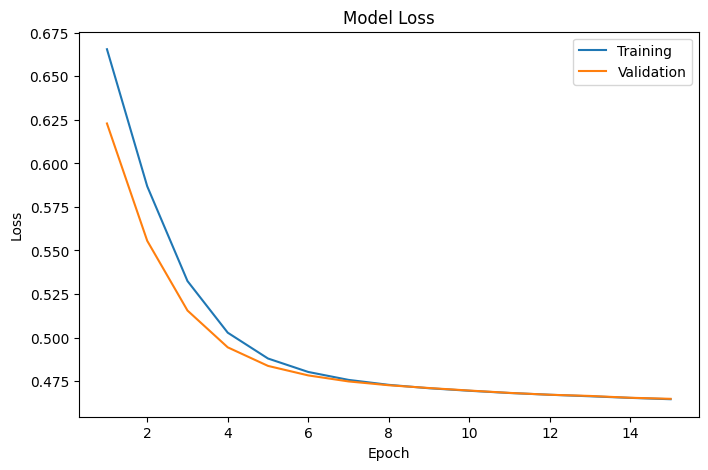

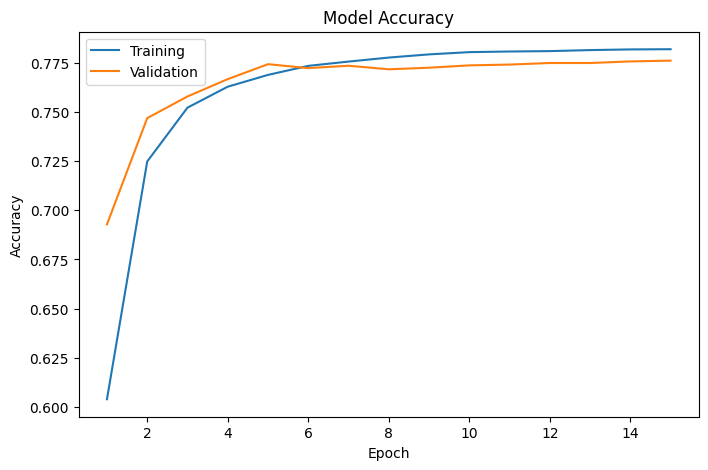

Raw AUC: 0.855


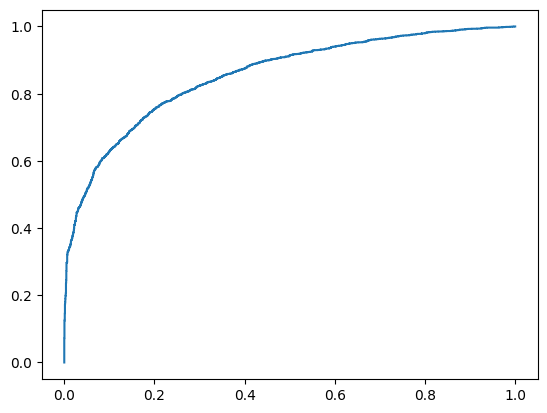

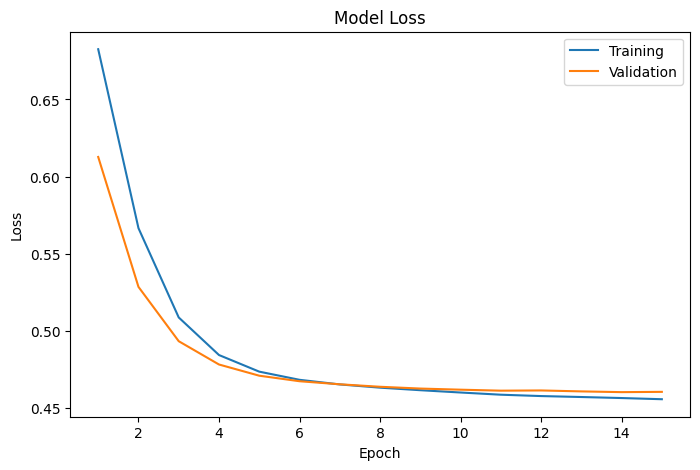

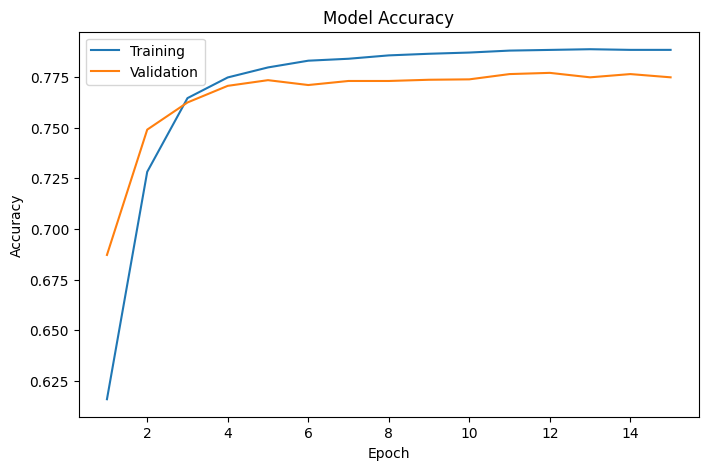

Derived AUC: 0.856


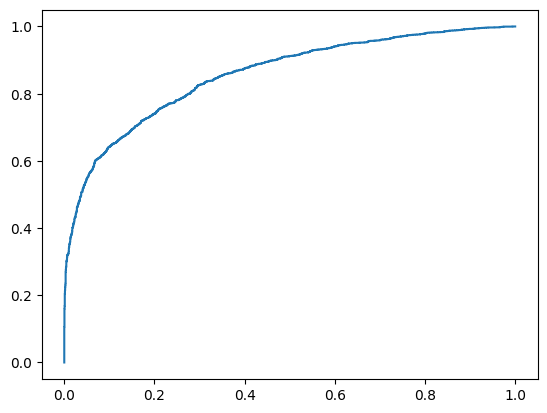

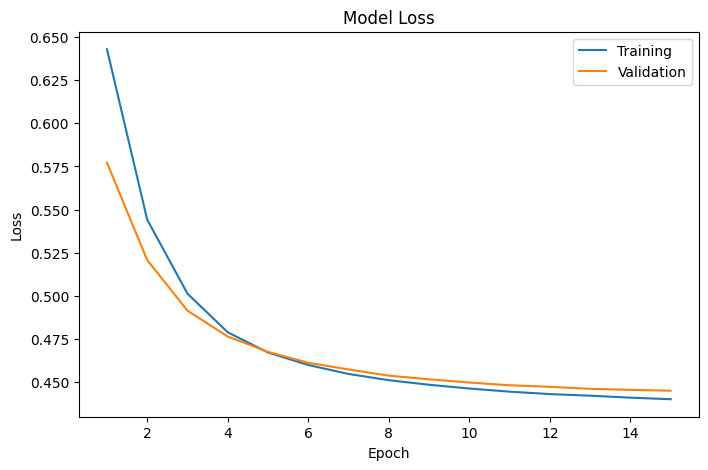

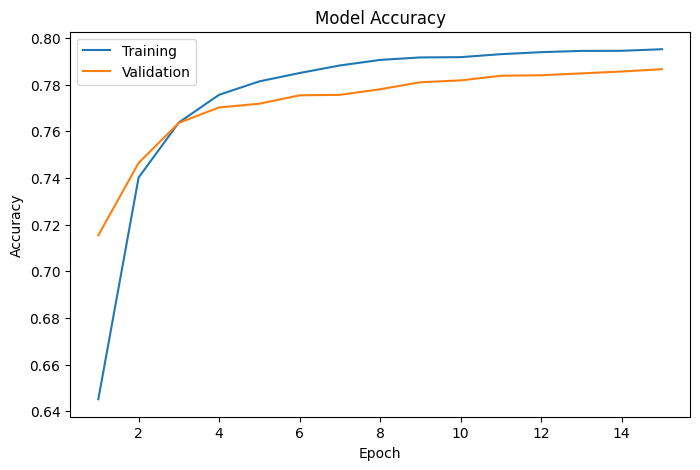

All AUC: 0.867


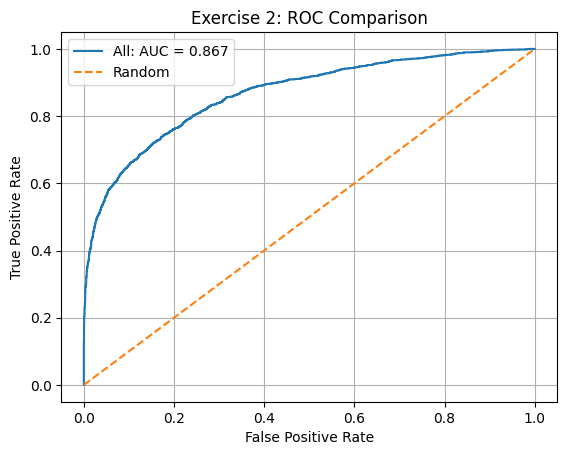

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score

feature_groups = {
    "Raw": RawNames,
    "Derived": FeatureNames,
    "All": VarNames[1:]
}

models_2 = {}
scalers_2 = {}
scores_2 = {}

plt.figure(figsize=(8, 6))

for name, columns in feature_groups.items():

    scaler = StandardScaler()

    train_data = scaler.fit_transform(Train_Sample[columns])
    validation_data = scaler.transform(Val_Sample[columns])

    model = Sequential([
        Input(shape=(len(columns),)),
        Dense(16, activation="relu"),
        Dense(8, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_data,
        y_Train,
        validation_data=(validation_data, y_Val),
        epochs=15,
        batch_size=1024,
        verbose=0
    )

    plot_history(history)

    predictions = model.predict(validation_data, verbose=0).ravel()

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_Val, predictions
    )

    auc_score = roc_auc_score(y_Val, predictions)

    models_2[name] = model
    scalers_2[name] = scaler
    scores_2[name] = auc_score

    plt.figure(1)
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name}: AUC = {auc_score:.3f}"
    )

    print(name, "AUC:", round(auc_score, 3))

plt.figure(1)
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 2: ROC Comparison")
plt.legend()
plt.grid()
plt.show()

## Exercise 3

Design and implement at least 3 different DNN models. Train them and compare performance. You may try different architectures, loss functions, and optimizers to see if there is an effect.

<Figure size 800x600 with 0 Axes>

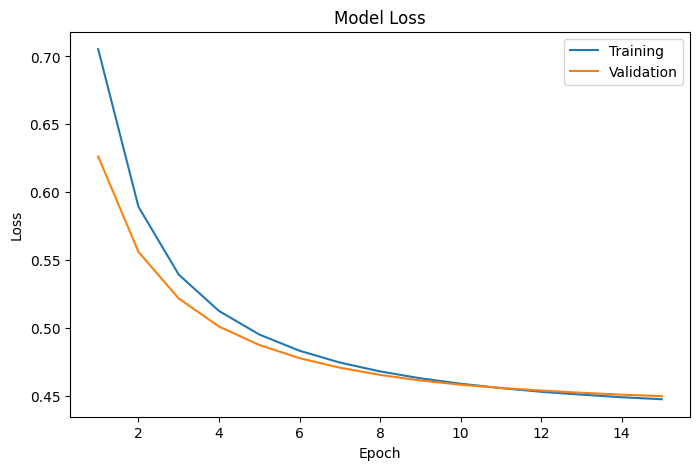

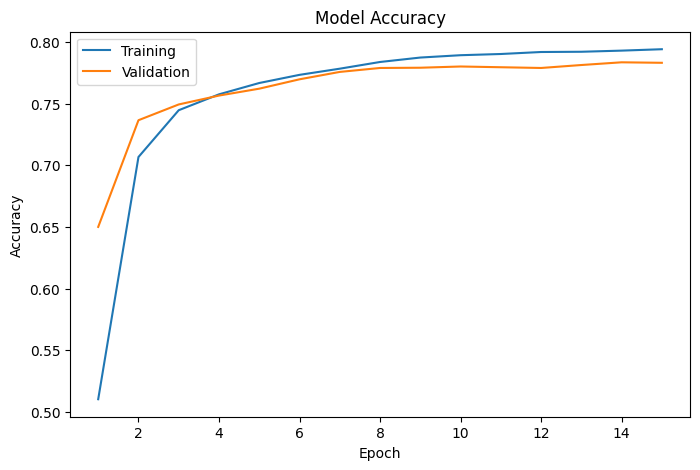

Model 1 AUC: 0.865


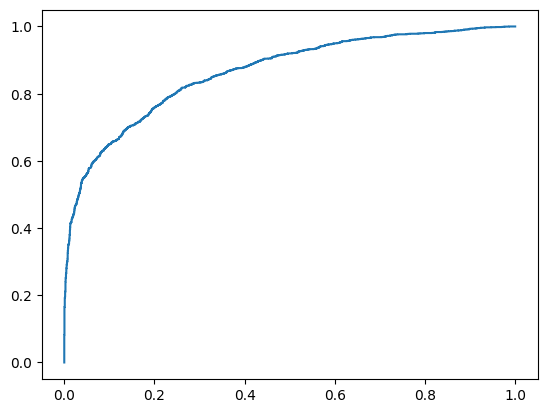

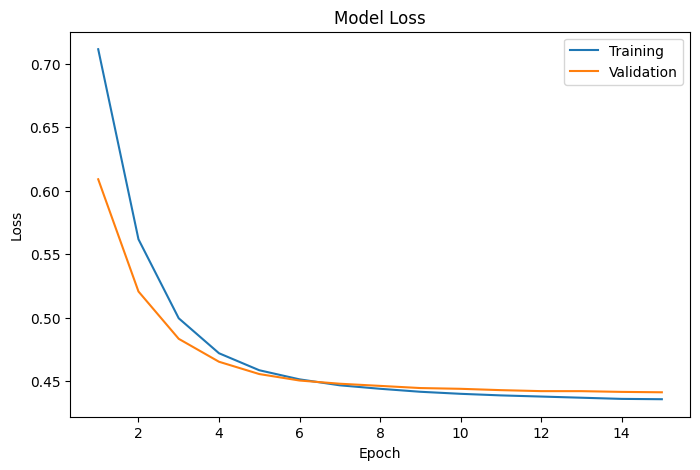

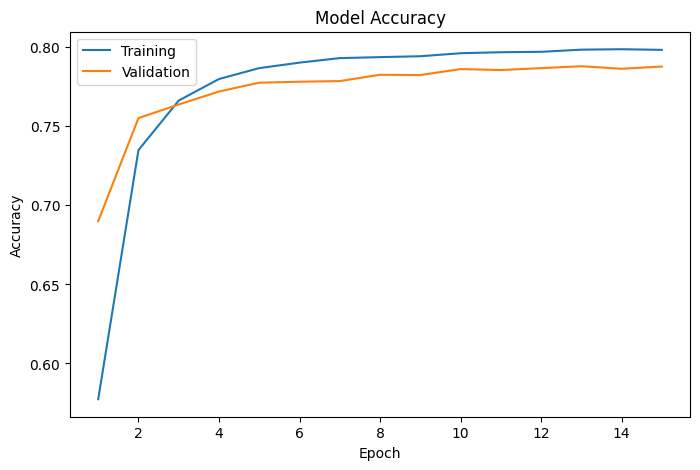

Model 2 AUC: 0.869


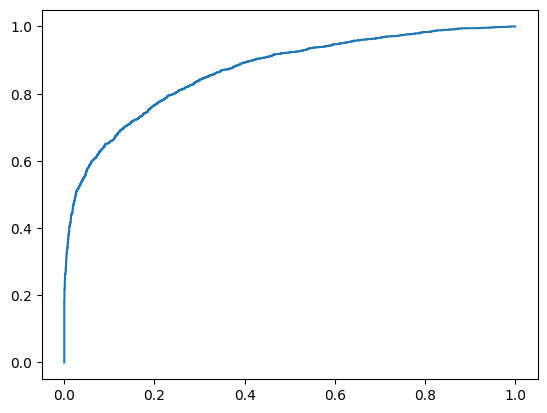

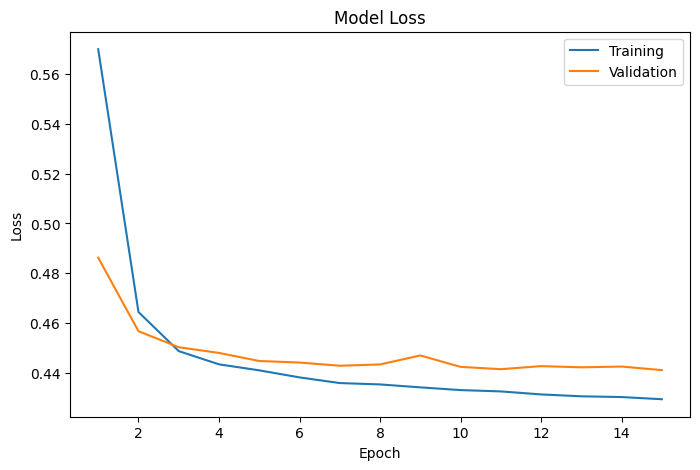

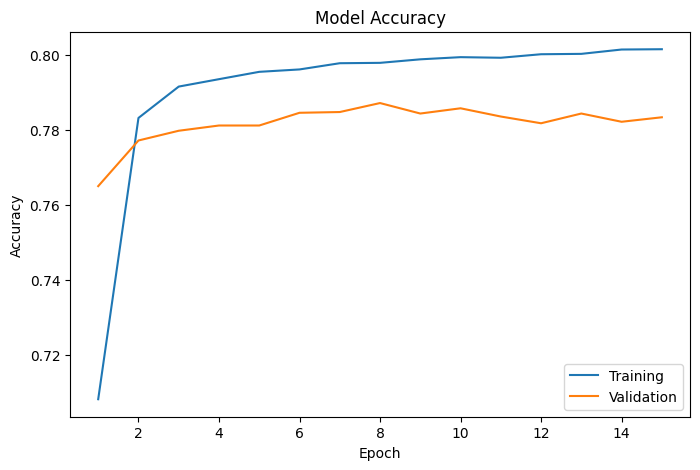

Model 3 AUC: 0.869


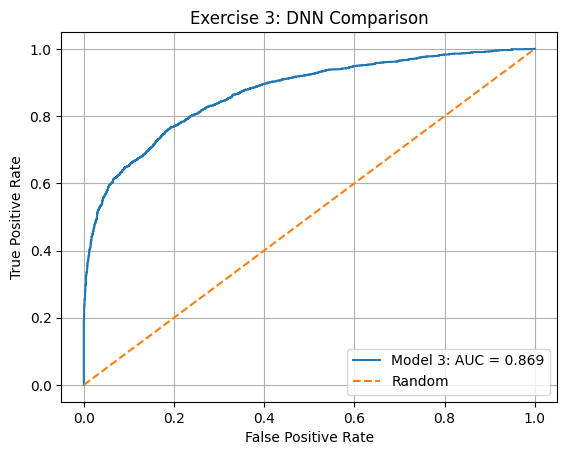

Best DNN: Model 3
Best validation AUC: 0.869209879682226


In [8]:
scaler_3 = StandardScaler()

train_data = scaler_3.fit_transform(X_Train)
validation_data = scaler_3.transform(X_Val)

model_sizes = {
    "Model 1": [16],
    "Model 2": [32, 16],
    "Model 3": [64, 32, 16]
}

models_3 = {}
scores_3 = {}

plt.figure(figsize=(8, 6))

for name, sizes in model_sizes.items():

    model = Sequential()
    model.add(Input(shape=(18,)))

    for size in sizes:
        model.add(Dense(size, activation="relu"))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_data,
        y_Train,
        validation_data=(validation_data, y_Val),
        epochs=15,
        batch_size=1024,
        verbose=0
    )

    plot_history(history)

    predictions = model.predict(validation_data, verbose=0).ravel()

    auc_score = roc_auc_score(y_Val, predictions)

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_Val, predictions
    )

    models_3[name] = model
    scores_3[name] = auc_score

    plt.figure(1)
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name}: AUC = {auc_score:.3f}"
    )

    print(name, "AUC:", round(auc_score, 3))

plt.figure(1)
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 3: DNN Comparison")
plt.legend()
plt.grid()
plt.show()

best_model_name = max(scores_3, key=scores_3.get)

print("Best DNN:", best_model_name)
print("Best validation AUC:", scores_3[best_model_name])

## Exercise 4

Repeat Exercise 4 from Lab 8 (parts b and c), adding your best performing DNN as one of the models. Choose your best DNN using the validation sample, then compare on the test sample.

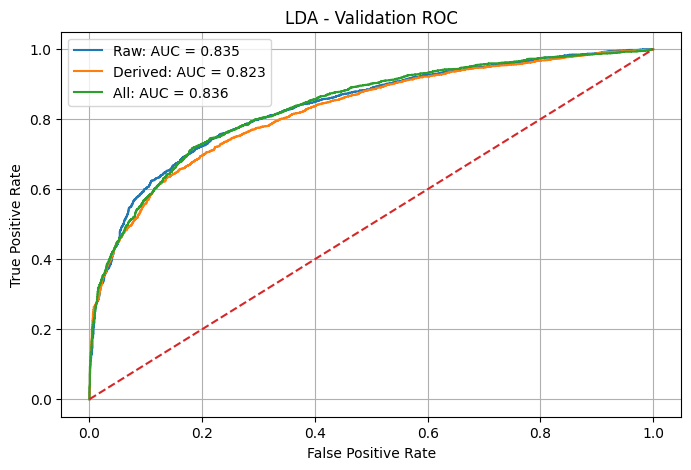

LDA best features: All
Validation AUC: 0.836


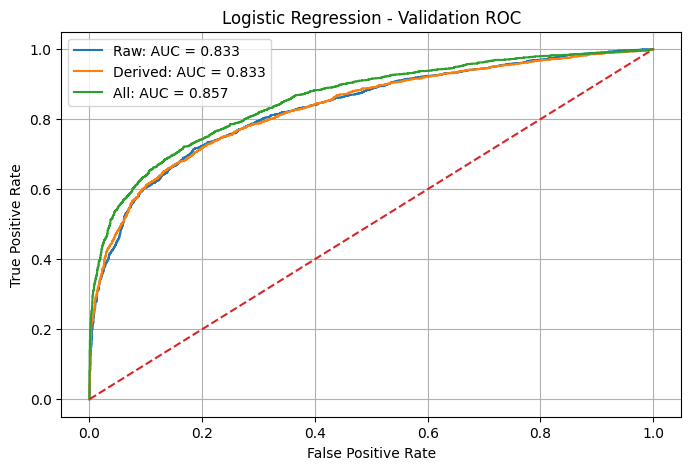

Logistic Regression best features: All
Validation AUC: 0.857


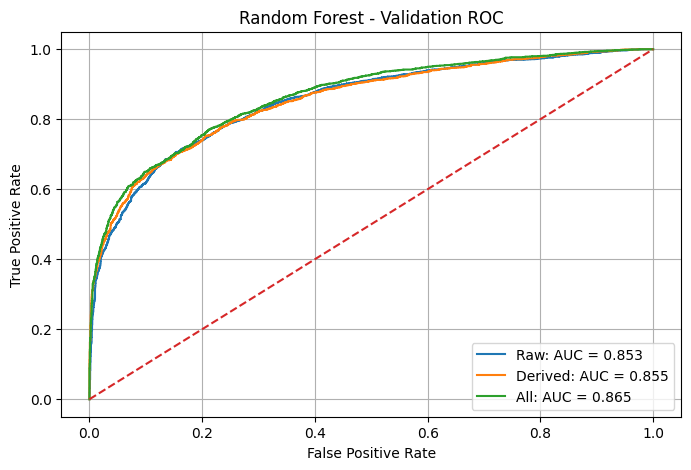

Random Forest best features: All
Validation AUC: 0.865


/home/mxm3146/Data-3402/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/home/mxm3146/Data-3402/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


LDA Validation AUC: 0.836
LDA Test AUC: 0.837
Logistic Regression Validation AUC: 0.857
Logistic Regression Test AUC: 0.86
Random Forest Validation AUC: 0.865
Random Forest Test AUC: 0.864
DNN Validation AUC: 0.869
DNN Test AUC: 0.866


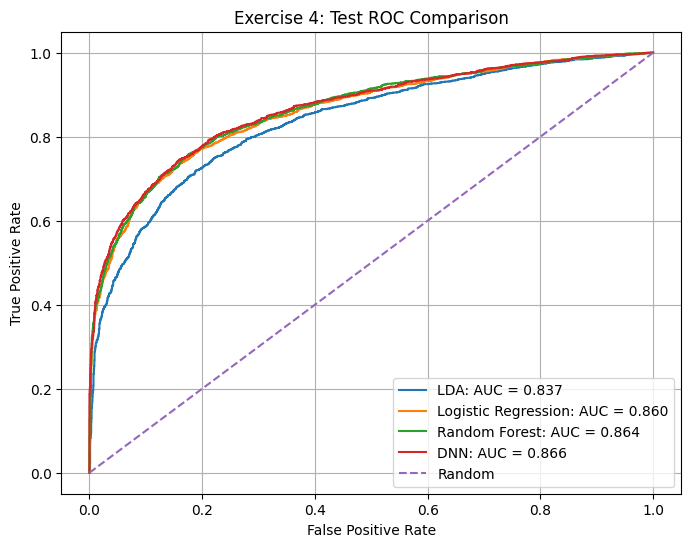

Best method: DNN
 Expected Signal  Expected Background  Best Cut  Validation Significance  Test Significance
              10                  100    0.7827                   1.8003             1.7822
             100                 1000    0.7827                   5.6932             5.6359
            1000                10000    0.7827                  18.0033            17.8224
           10000               100000    0.7827                  56.9316            56.3593


In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

classical_models = {
    "LDA": LinearDiscriminantAnalysis(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=40,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
}

best_classical = {}

for name, classifier in classical_models.items():

    best_score = -1

    plt.figure(figsize=(8, 5))

    for group_name, columns in feature_groups.items():

        scaler = StandardScaler()

        train_data = scaler.fit_transform(Train_Sample[columns])
        validation_data = scaler.transform(Val_Sample[columns])

        model = clone(classifier)
        model.fit(train_data, y_Train)

        predictions = model.predict_proba(validation_data)[:, 1]

        auc_score = roc_auc_score(y_Val, predictions)

        false_positive_rate, true_positive_rate, thresholds = roc_curve(
            y_Val, predictions
        )

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{group_name}: AUC = {auc_score:.3f}"
        )

        if auc_score > best_score:
            best_score = auc_score

            best_classical[name] = {
                "model": model,
                "scaler": scaler,
                "columns": columns,
                "group": group_name,
                "auc": auc_score
            }

    plt.plot([0, 1], [0, 1], "--")
    plt.title(name + " - Validation ROC")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.show()

    print(name, "best features:", best_classical[name]["group"])
    print("Validation AUC:", round(best_score, 3))


best_name_2 = max(scores_2, key=scores_2.get)
best_name_3 = max(scores_3, key=scores_3.get)

if scores_2[best_name_2] > scores_3[best_name_3]:

    best_dnn = models_2[best_name_2]
    dnn_scaler = scalers_2[best_name_2]
    dnn_columns = feature_groups[best_name_2]

else:

    best_dnn = models_3[best_name_3]
    dnn_scaler = scaler_3
    dnn_columns = VarNames[1:]


validation_predictions = {}
test_predictions = {}
validation_scores = {}
test_scores = {}

for name, information in best_classical.items():

    model = information["model"]
    scaler = information["scaler"]
    columns = information["columns"]

    validation_data = scaler.transform(Val_Sample[columns])
    test_data = scaler.transform(Test_Sample[columns])

    validation_predictions[name] = model.predict_proba(validation_data)[:, 1]
    test_predictions[name] = model.predict_proba(test_data)[:, 1]


validation_data = dnn_scaler.transform(Val_Sample[dnn_columns])
test_data = dnn_scaler.transform(Test_Sample[dnn_columns])

validation_predictions["DNN"] = best_dnn.predict(
    validation_data, verbose=0
).ravel()

test_predictions["DNN"] = best_dnn.predict(
    test_data, verbose=0
).ravel()


plt.figure(figsize=(8, 6))

for name, predictions in test_predictions.items():

    validation_auc = roc_auc_score(
        y_Val, validation_predictions[name]
    )

    test_auc = roc_auc_score(y_Test, predictions)

    validation_scores[name] = validation_auc
    test_scores[name] = test_auc

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_Test, predictions
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name}: AUC = {test_auc:.3f}"
    )

    print(name, "Validation AUC:", round(validation_auc, 3))
    print(name, "Test AUC:", round(test_auc, 3))


plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 4: Test ROC Comparison")
plt.legend()
plt.grid()
plt.show()


best_method = max(validation_scores, key=validation_scores.get)

print("Best method:", best_method)

validation_prediction = validation_predictions[best_method]
test_prediction = test_predictions[best_method]

false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_Val, validation_prediction
)

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for expected_signal, expected_background in scenarios:

    selected_signal = expected_signal * true_positive_rate
    selected_background = expected_background * false_positive_rate

    significance = np.divide(
        selected_signal,
        np.sqrt(selected_signal + selected_background),
        out=np.zeros_like(selected_signal),
        where=(selected_signal + selected_background) > 0
    )

    best_index = np.argmax(significance)
    best_cut = thresholds[best_index]

    signal_efficiency = np.mean(
        test_prediction[y_Test == 1] >= best_cut
    )

    background_efficiency = np.mean(
        test_prediction[y_Test == 0] >= best_cut
    )

    final_signal = expected_signal * signal_efficiency
    final_background = expected_background * background_efficiency

    if final_signal + final_background > 0:
        test_significance = final_signal / np.sqrt(
            final_signal + final_background
        )
    else:
        test_significance = 0

    results.append([
        expected_signal,
        expected_background,
        best_cut,
        significance[best_index],
        test_significance
    ])


results_table = pd.DataFrame(
    results,
    columns=[
        "Expected Signal",
        "Expected Background",
        "Best Cut",
        "Validation Significance",
        "Test Significance"
    ]
)

print(results_table.round(4).to_string(index=False))